# IBL Dataset Exploration: Priors, Choice History, and Left/Right Choice Probability

**Goal of this notebook.** This is a first, documented pass at the IBL (International Brain Laboratory) public
behavioral dataset, done the way it would actually be explored for a project proposal: connect to the real
data source, pull real sessions, look hard at what is actually in the tables (including what is broken,
missing, or surprising), and produce a first quantitative answer to the guiding questions before committing
to a full analysis plan.

**Research questions this notebook is scoping data for:**

> **Q (Persian, as given):** پرایورها شامل متغیرهای موثر (یادگیری گذرا، پاداش، محرک حسی، جهت بلوک، انتخاب
> ترایال قبل و ترایال‌های قبل‌تر) چطور احتمال انتخاب سمت چپ یا راست موش را در تسک IBL تغییر می‌دهد؟
>
> **Q (English):** How do priors — through effective variables including transient learning, reward, sensory
> stimulus (contrast), block direction, the previous trial's choice, and choices further back — change the
> probability that the mouse chooses left vs. right in the IBL task?
>
> **Q1 (Persian, as given):** وقتی outcome یا evidence جدید می‌آید، representation prior در مغز از Trial t به
> t+1 چگونه تغییر می‌کند؟
>
> **Q1 (English):** When new outcome/evidence arrives, how does the brain's representation of the prior change
> from trial *t* to trial *t+1*?

**Project-template question this notebook directly answers (Q6):** *What information from the dataset will
you use, and what have you learned from exploring it so far?* — answered below with real extracted data,
concrete preliminary plots, and practical issues actually encountered while pulling the data.


## 1. Data source

The IBL ran a single standardized decision task (a visual 2-alternative forced-choice task on a wheel-turning
rig) across ~9-10 labs, with mice tracked from their very first training session through to expert,
Neuropixels-recorded sessions ("Brain-wide Map"). All of this is public and queryable through IBL's own
**ONE-api** (Open Neurophysiology Environment), which talks to a read-only mirror of their Alyx database at
`openalyx.internationalbrainlab.org`. No account/registration is required — IBL publishes a shared read-only
login (`intbrainlab` / `international`) specifically so anyone can pull the public release data. This is the
same access path used in IBL's and Neuromatch Academy's own tutorials.

Packages needed: `ONE-api` (data access), `pandas`/`numpy` (tables), `matplotlib` (plots), `statsmodels`
(GLM). `ibllib`/`brainbox` are only needed if we later want spike-sorted Neuropixels data — not required for
the behavioral analysis below.


In [1]:
# Run once if these aren't already installed:
# !pip install ONE-api pandas numpy matplotlib statsmodels

from one.api import ONE
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

pd.set_option('display.max_columns', 30)

one = ONE(base_url='https://openalyx.internationalbrainlab.org', password='international', silent=True)
print('Connected to:', one.alyx.base_url)
print('one-api instance type:', type(one))

Connected to: https://openalyx.internationalbrainlab.org
one-api instance type: <class 'one.api.OneAlyx'>


## 2. Choosing what to pull

The full public release has hundreds of sessions across ~100+ mice. For a first pass, depth on one animal is
more useful than breadth across many: a single subject that was tracked from naive training through the
biased-block stage into Neuropixels recording gives us, in one continuous behavioral record, exactly the
"transient learning" axis the research question asks about, plus the full prior/block manipulation once it's
introduced.

We use **KS023** — the example subject IBL's own `ONE` documentation uses to demonstrate `one.search()`
(so it's a reliable, well-behaved animal to build a pipeline against), from **cortexlab** (UCL), part of the
`ibl_neuropixel_brainwide_01` project. Checking its actual session history shows it happens to have exactly
the trajectory we want: `trainingChoiceWorld` (no block structure) through `biasedChoiceWorld`
(block-structured priors) to `ephysChoiceWorld` (block-structured, Neuropixels-recorded) — all 40 sessions
downloaded without error, and its easy-trial accuracy (see §6d) shows clean, fast learning rather than messy
or degenerate behavior. It was **not** selected by filtering for a particular result — this is a single
animal, so any subject-specific idiosyncrasy is a caveat on generalization; scaling this pipeline to more
subjects/labs later is a one-line change (see §6).


In [2]:
subject = 'KS023'
eids, details = one.search(subject=subject, details=True)
print(f'Sessions found for {subject}: {len(eids)}')
print(f'Date range: {min(d["date"] for d in details)}  to  {max(d["date"] for d in details)}')

protocol_counts = pd.Series([d['task_protocol'] for d in details]).value_counts()
print('\nSessions by task protocol:')
print(protocol_counts)

Sessions found for KS023: 40
Date range: 2019-10-01  to  2019-12-11

Sessions by task protocol:
_iblrig_tasks_biasedChoiceWorld6.1.3      10
_iblrig_tasks_biasedChoiceWorld6.0.5       9
_iblrig_tasks_biasedChoiceWorld6.0.6       8
_iblrig_tasks_ephysChoiceWorld6.1.3        5
_iblrig_tasks_trainingChoiceWorld6.0.5     3
_iblrig_tasks_trainingChoiceWorld6.0.3     2
_iblrig_tasks_trainingChoiceWorld6.0.2     2
_iblrig_tasks_trainingChoiceWorld5.3.1     1
Name: count, dtype: int64


## 3. Extracting the trial-level data

For each session we pull the `trials` object with `one.load_object(eid, 'trials')`, which downloads (and
locally caches) the `_ibl_trials.table.pqt` file and returns it as a Bunch we convert to a DataFrame. We tag
each session's trials with its `eid`, calendar date, and task protocol so we can reconstruct training order
and stage later.


In [3]:
rows = []
for eid, d in zip(eids, details):
    trials = one.load_object(eid, 'trials')
    tdf = trials.to_df()
    tdf['eid'] = str(eid)
    tdf['session_date'] = d['date']
    tdf['task_protocol'] = d['task_protocol']
    rows.append(tdf)

all_trials = pd.concat(rows, ignore_index=True)
print('Total trials pulled:', len(all_trials))
print('Columns:', list(all_trials.columns))
all_trials.head()

C:\Users\sush\AppData\Local\Programs\Python\Python312\Lib\site-packages\one\util.py:464: ALFWarning: Multiple revisions: "", "2025-03-03"
  warnings.warn(f'Multiple revisions: {rev_list}', alferr.ALFWarning)


C:\Users\sush\AppData\Local\Programs\Python\Python312\Lib\site-packages\one\util.py:464: ALFWarning: Multiple revisions: "", "2025-03-03"
  warnings.warn(f'Multiple revisions: {rev_list}', alferr.ALFWarning)


C:\Users\sush\AppData\Local\Programs\Python\Python312\Lib\site-packages\one\util.py:464: ALFWarning: Multiple revisions: "", "2025-03-03"
  warnings.warn(f'Multiple revisions: {rev_list}', alferr.ALFWarning)


C:\Users\sush\AppData\Local\Programs\Python\Python312\Lib\site-packages\one\util.py:464: ALFWarning: Multiple revisions: "", "2025-03-03"
  warnings.warn(f'Multiple revisions: {rev_list}', alferr.ALFWarning)


Total trials pulled: 20815
Columns: ['stimOn_times', 'goCue_times', 'choice', 'firstMovement_times', 'response_times', 'contrastRight', 'feedbackType', 'rewardVolume', 'feedback_times', 'probabilityLeft', 'contrastLeft', 'intervals_0', 'intervals_1', 'eid', 'session_date', 'task_protocol', 'goCueTrigger_times', 'intervals_bpod_0', 'intervals_bpod_1', 'quiescencePeriod', 'stimOffTrigger_times', 'stimOff_times', 'stimOnTrigger_times']


,stimOn_times,goCue_times,choice,firstMovement_times,response_times,contrastRight,feedbackType,rewardVolume,feedback_times,probabilityLeft,contrastLeft,intervals_0,intervals_1,eid,session_date,task_protocol,goCueTrigger_times,intervals_bpod_0,intervals_bpod_1,quiescencePeriod,stimOffTrigger_times,stimOff_times,stimOnTrigger_times
0,10.373017,10.374050,-1.0,10.483393,10.793886,1.0000,1.0,1.5,10.793874,0.5,NaN,9.692386,12.293807,c6d5cea7-e1c4-48e1-8898-78e039fabf2b,2019-12-11,_iblrig_tasks_ephysChoiceWorld6.1.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,13.339683,13.340683,-1.0,13.512393,13.975908,1.0000,1.0,1.5,13.975886,0.5,NaN,12.767308,15.475794,c6d5cea7-e1c4-48e1-8898-78e039fabf2b,2019-12-11,_iblrig_tasks_ephysChoiceWorld6.1.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,17.356377,17.357277,-1.0,17.554393,17.828890,0.0625,1.0,1.5,17.828896,0.5,NaN,15.912290,19.328828,c6d5cea7-e1c4-48e1-8898-78e039fabf2b,2019-12-11,_iblrig_tasks_ephysChoiceWorld6.1.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,20.323010,20.323910,1.0,26.815393,27.111630,NaN,1.0,1.5,27.111656,0.5,0.125,19.799030,28.611556,c6d5cea7-e1c4-48e1-8898-78e039fabf2b,2019-12-11,_iblrig_tasks_ephysChoiceWorld6.1.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,32.989328,32.990361,1.0,33.332393,33.493254,NaN,1.0,1.5,33.493277,0.5,0.250,29.108554,34.993175,c6d5cea7-e1c4-48e1-8898-78e039fabf2b,2019-12-11,_iblrig_tasks_ephysChoiceWorld6.1.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. What's actually in the `trials` table

| column | meaning |
|---|---|
| `stimOn_times`, `goCue_times` | time (s) the stimulus / go-cue appeared |
| `choice` | `-1` / `0` / `1` — raw wheel-response code (sign convention verified empirically below) |
| `firstMovement_times`, `response_times` | time of first wheel movement / recorded response |
| `contrastLeft`, `contrastRight` | stimulus contrast (0-1) on that side; the *other* side is `NaN` by design (only one side has a stimulus per trial) |
| `feedbackType` | `+1` reward, `-1` no reward / timeout |
| `rewardVolume` | µL delivered (0 if unrewarded) |
| `probabilityLeft` | the experimenter-controlled **block prior**: P(stimulus on the left) for that trial — this is the "prior"/"block direction" variable |
| `intervals_0`, `intervals_1` | trial start/end times |

This directly maps onto the variables the research question asks about: **sensory stimulus** =
`contrastLeft`/`contrastRight`, **block direction/prior** = `probabilityLeft`, **reward** = `feedbackType`,
**previous trial choice / further back** = lagged `choice`, **transient learning** = session order /
`task_protocol` stage.


In [4]:
print('Missing-value fraction per column:')
print(all_trials.isna().mean().sort_values(ascending=False))

Missing-value fraction per column:
stimOff_times           0.865193
intervals_bpod_1        0.865049
stimOffTrigger_times    0.865049
stimOnTrigger_times     0.865049
quiescencePeriod        0.865049
intervals_bpod_0        0.865049
goCueTrigger_times      0.865049
contrastLeft            0.500456
contrastRight           0.499544
firstMovement_times     0.061062
rewardVolume            0.054624
stimOn_times            0.036464
feedback_times          0.002354
goCue_times             0.000000
choice                  0.000000
feedbackType            0.000000
response_times          0.000000
session_date            0.000000
intervals_0             0.000000
probabilityLeft         0.000000
eid                     0.000000
intervals_1             0.000000
task_protocol           0.000000
dtype: float64


**Practical issue #1 — missingness is not all the same kind of problem.**
- `contrastLeft`/`contrastRight` are ~50% `NaN` *by design*: each trial has a stimulus on only one side, so
  the other column is structurally empty. Not a data-quality problem, just needs `signed_contrast =
  contrastRight` where present else `-contrastLeft`.
- `stimOff_times`, `intervals_bpod_*`, `stimOnTrigger_times`, `goCueTrigger_times`, `quiescencePeriod` are
  missing in **~86%** of trials — these fields were only logged starting with a later task-software revision.
  Any analysis using these fields has to be restricted to the sessions that have them, or drop them entirely
  (we don't need them for the choice-probability question).
- `firstMovement_times` (~6% missing) and `stimOn_times` (~3.6% missing) have small amounts of real missing
  data (dropped frames / logging glitches) that should be excluded per-analysis rather than imputed.


In [5]:
print('choice value counts (0 = no response / omission trial):')
print(all_trials['choice'].value_counts())
n_omit = (all_trials['choice'] == 0).sum()
print(f'\nOmission trials: {n_omit} / {len(all_trials)} ({n_omit/len(all_trials):.3%}) -- excluded from choice analyses below')

choice value counts (0 = no response / omission trial):
choice
-1.0    11001
 1.0     9763
 0.0       51
Name: count, dtype: int64

Omission trials: 51 / 20815 (0.245%) -- excluded from choice analyses below


**Practical issue #2 — a small number of omission trials.** In 51 of 20,815 trials (0.25%) the mouse
never responded (`choice == 0`, `feedbackType == -1`, no `rewardVolume`). These are dropped from all
choice-probability analyses below since "P(choose left/right)" isn't defined for a non-response.

**Practical issue #3 — the `choice` sign convention has to be checked, not assumed.** IBL documentation
states a convention for the sign of `choice`, but rather than trust that from memory, we verify it directly:
on **correct** trials, the mouse's response must match the side the stimulus was on.


In [6]:
correct = all_trials[all_trials['feedbackType'] == 1]

right_stim_correct = correct.dropna(subset=['contrastRight'])
left_stim_correct = correct.dropna(subset=['contrastLeft'])

print('choice value on CORRECT trials with a RIGHT-side stimulus (contrastRight set):')
print(right_stim_correct['choice'].value_counts())
print('\nchoice value on CORRECT trials with a LEFT-side stimulus (contrastLeft set):')
print(left_stim_correct['choice'].value_counts())

choice value on CORRECT trials with a RIGHT-side stimulus (contrastRight set):
choice
-1.0    8916
Name: count, dtype: int64

choice value on CORRECT trials with a LEFT-side stimulus (contrastLeft set):
choice
1.0    8286
Name: count, dtype: int64


This settles it unambiguously: on correct trials with a right-side stimulus, `choice` is **always
-1**; with a left-side stimulus, `choice` is **always +1**. So: **`choice == -1` → rightward choice**,
**`choice == 1` → leftward choice**, **`choice == 0` → no response**. We encode this as `choice_right`
(1 = chose right, 0 = chose left, `NaN` = omission) for everything that follows.


## 5. Derived variables

Building the columns the research question actually needs:
- `signed_contrast`: negative = left stimulus, positive = right stimulus, magnitude = contrast (**sensory stimulus**)
- `choice_right`: 1 = chose right, 0 = chose left
- `prior_bias_right = 0.5 - probabilityLeft`: positive when the block favors a right-side stimulus (**block direction / prior**)
- `session_index`: chronological session order for this subject (**transient learning** axis)
- `stage`: `training` / `biased` / `ephys`, parsed from `task_protocol`
- lagged choice/outcome terms at *t*-1 and *t*-2, computed **within session** so history never leaks across a session boundary (**previous trial choice and choices further back**)


In [7]:
df = all_trials.copy()

session_order = df.drop_duplicates('eid')[['eid', 'session_date']].sort_values('session_date')
session_order['session_index'] = range(len(session_order))
df = df.merge(session_order[['eid', 'session_index']], on='eid', how='left')

df['stage'] = df['task_protocol'].apply(
    lambda p: 'training' if 'training' in p else ('biased' if 'biased' in p else 'ephys'))

df['signed_contrast'] = np.where(df['contrastRight'].notna(), df['contrastRight'],
                          np.where(df['contrastLeft'].notna(), -df['contrastLeft'], np.nan))
df['choice_right'] = np.where(df['choice'] == -1, 1, np.where(df['choice'] == 1, 0, np.nan))
df['rewarded'] = (df['feedbackType'] == 1).astype(float)
df.loc[df['choice'] == 0, 'rewarded'] = np.nan
df['reaction_time'] = df['response_times'] - df['stimOn_times']

print('Trials per stage:')
print(df['stage'].value_counts())

print('\nprobabilityLeft values actually used, by stage:')
for stage, sub in df.groupby('stage'):
    vals = sorted(sub['probabilityLeft'].unique())
    print(f'  {stage}: {vals if len(vals) <= 6 else f"{len(vals)} distinct values (not a clean 3-level block design)"}')

Trials per stage:
stage
biased      14572
training     3319
ephys        2924
Name: count, dtype: int64

probabilityLeft values actually used, by stage:
  biased: [np.float64(0.2), np.float64(0.5), np.float64(0.8)]
  ephys: [np.float64(0.2), np.float64(0.5), np.float64(0.8)]
  training: 11 distinct values (not a clean 3-level block design)


**Practical issue #4 — `probabilityLeft` is only a meaningful "block prior" in `biased`/`ephys`
sessions.** In `training` sessions the column takes many different values (an artifact of the pre-bias task
code, not a real experimenter-set block prior) — before the biased blocks were introduced there was no fixed
prior structure. Only `biased` and `ephys` stage sessions have the intended clean 3-level design
(`probabilityLeft ∈ {0.2, 0.5, 0.8}`). **All prior/block analyses below are restricted to those two stages**;
`training` sessions are kept only for the session-level learning-curve plot, where the block prior is
irrelevant.


In [8]:
# drop omission trials, then compute within-session choice/outcome history
df_valid = df[df['choice'] != 0].copy()
df_valid = df_valid.sort_values(['session_index', 'intervals_0'])

g = df_valid.groupby('eid', sort=False)
df_valid['prev_choice_right'] = g['choice_right'].shift(1)
df_valid['prev_rewarded']     = g['rewarded'].shift(1)
df_valid['prev2_choice_right'] = g['choice_right'].shift(2)
df_valid['prev2_rewarded']     = g['rewarded'].shift(2)

block_df = df_valid[df_valid['stage'].isin(['biased', 'ephys'])].copy()
block_df['prior_bias_right'] = 0.5 - block_df['probabilityLeft']

print('Trials with a valid block prior (biased+ephys):', len(block_df))
print(block_df['probabilityLeft'].value_counts())

Trials with a valid block prior (biased+ephys): 17470
probabilityLeft
0.2    7358
0.8    7238
0.5    2874
Name: count, dtype: int64


## 6. Preliminary plots

### 6a. The block manipulation itself

Before showing its effect on choice, it's worth just looking at the block structure IBL actually imposes:
`probabilityLeft` switches between 0.2 and 0.8 in runs of ~20-100 trials (after a short neutral 0.5 block at
the start of the session), never explicitly cued to the animal.


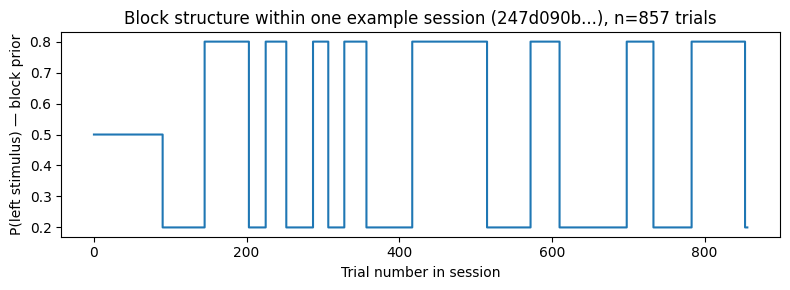

In [9]:
example_eid = block_df['eid'].value_counts().index[0]
ex = block_df[block_df['eid'] == example_eid].sort_values('intervals_0').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(ex.index, ex['probabilityLeft'], drawstyle='steps-post')
ax.set_xlabel('Trial number in session')
ax.set_ylabel('P(left stimulus) — block prior')
ax.set_title(f'Block structure within one example session ({example_eid[:8]}...), n={len(ex)} trials')
fig.tight_layout()
plt.show()

### 6b. Does the block prior actually shift choice? (psychometric curve by block)

Classic check: plot P(choose right) against signed contrast, separately for each block type. If the prior
matters, the curves should be **horizontally offset** near zero contrast (where the stimulus alone gives
little information and the animal has to fall back on its prior belief about the block).


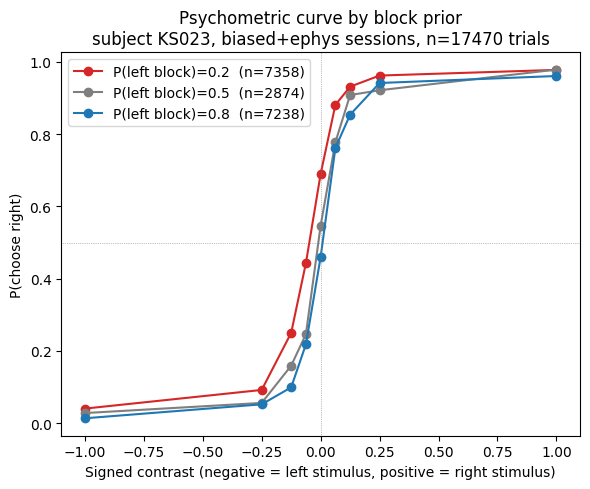

In [10]:
fig, ax = plt.subplots(figsize=(6, 5))
colors = {0.2: '#d62728', 0.5: '#7f7f7f', 0.8: '#1f77b4'}
for pleft, sub in block_df.groupby('probabilityLeft'):
    psych = sub.groupby('signed_contrast')['choice_right'].mean()
    n = sub.groupby('signed_contrast')['choice_right'].size()
    ax.plot(psych.index, psych.values, 'o-', color=colors.get(pleft, 'k'),
            label=f'P(left block)={pleft:.1f}  (n={n.sum()})')
ax.axhline(0.5, color='gray', lw=0.5, ls=':')
ax.axvline(0, color='gray', lw=0.5, ls=':')
ax.set_xlabel('Signed contrast (negative = left stimulus, positive = right stimulus)')
ax.set_ylabel('P(choose right)')
ax.set_title(f'Psychometric curve by block prior\nsubject {subject}, biased+ephys sessions, n={len(block_df)} trials')
ax.legend()
fig.tight_layout()
plt.show()

**Observation:** yes, clearly. Near zero contrast, P(choose right) is noticeably higher in the
P(left)=0.2 block (red, where right is objectively more likely correct) than in the P(left)=0.8 block (blue),
with the neutral P(left)=0.5 block in between. The three curves converge at high contrast, where the stimulus
alone is unambiguous and the prior stops mattering — exactly the pattern a Bayesian observer combining a
sensory likelihood with a block prior should produce, and the starting point for modeling how that prior
belief is represented and updated trial-to-trial (Q1).


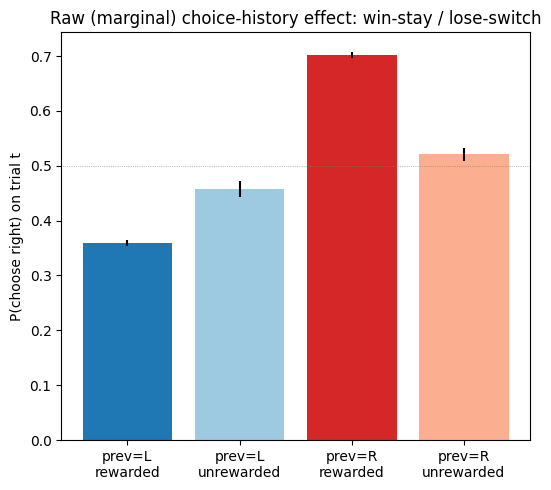

                                     mean  count
prev_choice_right prev_rewarded                 
0.0               0.0            0.457728   1171
                  1.0            0.359212   7007
1.0               0.0            0.520771   1661
                  1.0            0.702592   7599


In [11]:
hist_df = block_df.dropna(subset=['prev_choice_right', 'prev_rewarded'])

labels, vals, errs = [], [], []
for prev_choice in [0, 1]:
    for prev_rew in [1, 0]:
        sub = hist_df[(hist_df['prev_choice_right'] == prev_choice) & (hist_df['prev_rewarded'] == prev_rew)]
        vals.append(sub['choice_right'].mean())
        errs.append(sub['choice_right'].std() / np.sqrt(len(sub)))
        labels.append(f"prev={'R' if prev_choice==1 else 'L'}\n{'rewarded' if prev_rew==1 else 'unrewarded'}")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.bar(labels, vals, yerr=errs, color=['#1f77b4', '#9ecae1', '#d62728', '#fcae91'])
ax.axhline(0.5, color='gray', lw=0.5, ls=':')
ax.set_ylabel('P(choose right) on trial t')
ax.set_title('Raw (marginal) choice-history effect: win-stay / lose-switch')
fig.tight_layout()
plt.show()

print(hist_df.groupby(['prev_choice_right', 'prev_rewarded'])['choice_right'].agg(['mean', 'count']))

**Observation:** a textbook win-stay/lose-switch pattern in the raw marginals — after a **rewarded**
right choice, P(choose right) jumps to ~0.70; after a **rewarded** left choice it drops to ~0.36 (i.e. ~0.64
probability of repeating left). After an **unrewarded** trial of either side, the probability sits close to
chance (~0.46-0.52). So the previous choice matters a lot, but mostly when it was rewarded — at face value.
This raw version doesn't yet control for contrast or block, which is addressed in §7.


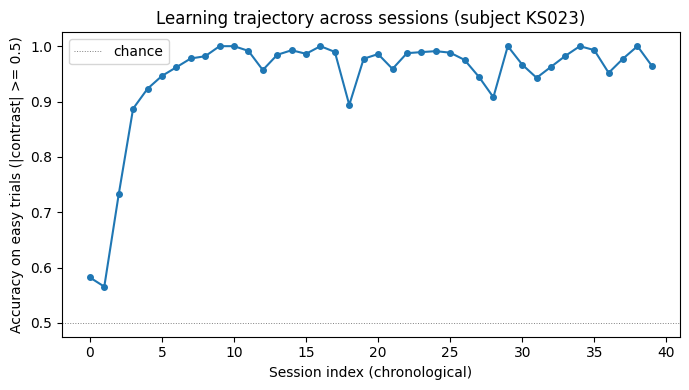

Session-index range covered by each stage:
          min  max
stage             
biased      8   34
ephys      35   39
training    0    7


In [12]:
perf = df_valid[df_valid['signed_contrast'].abs() >= 0.5].groupby('session_index').apply(
    lambda d: (d['rewarded'] == 1).mean())
stage_bounds = df_valid.groupby('stage')['session_index'].agg(['min', 'max'])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(perf.index, perf.values, 'o-', ms=4)
ax.axhline(0.5, color='gray', ls=':', lw=0.7, label='chance')
ax.set_xlabel('Session index (chronological)')
ax.set_ylabel('Accuracy on easy trials (|contrast| >= 0.5)')
ax.set_title(f'Learning trajectory across sessions (subject {subject})')
ax.legend()
fig.tight_layout()
plt.show()

print('Session-index range covered by each stage:')
print(stage_bounds)

**Observation:** clear "transient learning" — easy-trial accuracy rises from ~58% at session 0 to a
sustained ~95-100% plateau by around session 5, and stays there through the `biased` and `ephys` stages
(sessions 8-39). This tells us the "learning" variable in the research question is really two separate
regimes: (1) the steep naive→expert rise in `training` sessions (0-7), where there's no block structure yet,
and (2) small session-to-session drift once the animal is already expert and the block prior is active — the
more relevant regime for isolating a *prior* effect from a *skill-acquisition* effect, since ability to use
the block prior obviously can't be assessed before it exists.


## 7. A first quantitative model

Putting sensory stimulus, block prior, and choice history together in one logistic regression predicting
`choice_right`, so the effect of each "effective variable" from the research question can be read off as a
coefficient rather than eyeballed from separate marginal plots:

- `signed_contrast` — sensory stimulus
- `prior_bias_right` — block direction / prior
- `r_choice_prev{1,2}` = (signed previous choice) × (rewarded) at lag 1, 2 — reward-gated choice history
- `u_choice_prev{1,2}` = (signed previous choice) × (unrewarded) at lag 1, 2 — history from unrewarded trials, previous trial and further back
- `session_index_z` — transient learning / session drift (z-scored)


In [13]:
block_df['prev_choice_signed']  = 2 * block_df['prev_choice_right'] - 1
block_df['prev2_choice_signed'] = 2 * block_df['prev2_choice_right'] - 1
block_df['r_choice_prev1'] = block_df['prev_choice_signed']  * block_df['prev_rewarded']
block_df['u_choice_prev1'] = block_df['prev_choice_signed']  * (1 - block_df['prev_rewarded'])
block_df['r_choice_prev2'] = block_df['prev2_choice_signed'] * block_df['prev2_rewarded']
block_df['u_choice_prev2'] = block_df['prev2_choice_signed'] * (1 - block_df['prev2_rewarded'])
block_df['session_index_z'] = (block_df['session_index'] - block_df['session_index'].mean()) / block_df['session_index'].std()

regressors = ['signed_contrast', 'prior_bias_right', 'r_choice_prev1', 'u_choice_prev1',
              'r_choice_prev2', 'u_choice_prev2', 'session_index_z']
model_df = block_df.dropna(subset=['choice_right'] + regressors).copy()
print('Trials used in GLM:', len(model_df))

X = sm.add_constant(model_df[regressors])
y = model_df['choice_right']
full_model = sm.Logit(y, X).fit(disp=0)
print(full_model.summary())
print('\nOdds ratios:')
print(np.exp(full_model.params))

Trials used in GLM: 17406
                           Logit Regression Results                           
Dep. Variable:           choice_right   No. Observations:                17406
Model:                          Logit   Df Residuals:                    17398
Method:                           MLE   Df Model:                            7
Date:                Mon, 17 Aug 2026   Pseudo R-squ.:                  0.4682
Time:                        22:39:03   Log-Likelihood:                -6398.9
converged:                       True   LL-Null:                       -12032.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.2027      0.022      9.166      0.000       0.159       0.246
signed_contrast     10.0888      0.212     47.561      0.000       9.673      10.505
pr

**Observation:** every regressor is significant. `signed_contrast` dominates (as it should — it's the
actual evidence), `prior_bias_right` has a large positive, significant effect (OR ≈ 3.0) confirming the block
prior shifts choice even with contrast in the model, and both reward-gated and non-reward-gated choice
history remain significant out to lag 2.

**Practical issue #5 — quasi-separation.** statsmodels flags that ~17% of trials are almost perfectly
predicted — expected here, since at |contrast| = 100% the animal is essentially always correct, which is a
near-deterministic relationship between `signed_contrast` and `choice_right`. It doesn't invalidate the fit,
but it does mean the *sensory* term is swamping everything else. The standard fix used in the IBL literature
for isolating prior/history effects is to refit on **zero/near-zero-contrast trials only**, where the
stimulus carries almost no information and any systematic choice bias has to come from the prior or history.


In [14]:
low_c = model_df[model_df['signed_contrast'].abs() <= 0.0625].copy()
print('Near-zero-contrast trials (|contrast| <= 6.25%):', len(low_c))

low_regressors = ['prior_bias_right', 'r_choice_prev1', 'u_choice_prev1', 'r_choice_prev2', 'u_choice_prev2', 'session_index_z']
X_low = sm.add_constant(low_c[low_regressors])
y_low = low_c['choice_right']
low_model = sm.Logit(y_low, X_low).fit(disp=0)
print(low_model.summary())
print('\nOdds ratios:')
print(np.exp(low_model.params))

Near-zero-contrast trials (|contrast| <= 6.25%): 6778
                           Logit Regression Results                           
Dep. Variable:           choice_right   No. Observations:                 6778
Model:                          Logit   Df Residuals:                     6771
Method:                           MLE   Df Model:                            6
Date:                Mon, 17 Aug 2026   Pseudo R-squ.:                  0.1356
Time:                        22:39:03   Log-Likelihood:                -4009.2
converged:                       True   LL-Null:                       -4638.0
Covariance Type:            nonrobust   LLR p-value:                1.716e-268
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const                0.2612      0.027      9.603      0.000       0.208       0.314
prior_bias_right     1.6145      0.125     12.962      0.00

**Observation:** with the sensory term removed and only near-zero-contrast trials kept, the fit is
clean (no separation warning), and the block-prior effect is *stronger* once it isn't sharing variance with
contrast (OR ≈ 5.0 vs 3.0 in the full model) — consistent with the prior mattering most exactly when the
stimulus itself is uninformative, which is the operating regime any neural "prior representation" would need
to be doing real work in.

One genuinely interesting discrepancy worth flagging rather than smoothing over: the **raw marginal**
win-stay/lose-switch plot in §6 suggested reward mattered a lot (rewarded-stay much stronger than
unrewarded-stay). In the GLM, `u_choice_prev1` (unrewarded-trial history) is *not* smaller than
`r_choice_prev1` (rewarded-trial history) — if anything it's slightly larger. That means part of what looked
like a reward-driven effect in the raw marginals was actually confounded with contrast and block (correct/
rewarded trials aren't randomly distributed across contrast and block value). This is exactly the kind of
thing a "practical issue" should flag: **marginal effects and model-controlled effects can disagree**, and a
project built on this dataset should commit early to which one it's reporting.


## 8. Summary

**What information from the dataset we used:** the `trials` table (choice, contrastLeft/Right, feedbackType,
probabilityLeft, response/stimulus timestamps) for all 40 sessions of subject KS023, spanning naive training
through expert Neuropixels-recorded sessions — 20,815 trials total, 17,470 of them with a valid block-prior
structure.

**What we've learned so far, mapped onto the research question's variable list:**
- **Sensory stimulus** (contrast) is, unsurprisingly, the dominant driver of choice (§7).
- **Block direction / prior** (`probabilityLeft`) produces a clear, significant leftward/rightward shift in
  the psychometric curve, strongest exactly when contrast is uninformative (§6b, §7).
- **Reward** and **previous trial choice** (and choices 2 back) both leave a measurable trace in the current
  choice, but the *size* of that trace depends heavily on whether contrast/block are controlled for — the raw
  and model-based estimates disagree (§6c vs §7), which is itself a finding.
- **Transient learning**: a steep naive→expert rise over the first ~5 training sessions, then a much smaller
  but still significant session-to-session drift once the animal is expert and the block prior is active (§6d, §7).

**Practical issues found while extracting the data** (relevant to how any downstream analysis should be
scoped): task-version-dependent missing fields (~86% missing for some timing columns depending on rig
software version); `contrastLeft`/`contrastRight` missingness that is structural, not a data-quality problem;
a small (0.25%) but nonzero omission-trial rate; `probabilityLeft` only being a meaningful block prior in
`biased`/`ephys`-stage sessions, not `training`; the `choice` sign convention needing empirical verification
rather than being trusted from documentation; and quasi-separation in the full logistic model motivating a
contrast-restricted refit.

**What's still needed for Q1** (how the brain's representation of the prior updates from trial *t* to
*t*+1): everything above is behavioral. Q1 needs simultaneously recorded neural activity, which means moving
from `one.load_object(eid, 'trials')` to the Neuropixels side of ONE — `one.search_insertions(atlas_acronym=...)`
and `SpikeSortingLoader` (see the loading functions used in IBL's own `IBL_ONE_tutorial.ipynb`) — for
`ephys`-stage sessions of subjects like this one, in the regions IBL's own brain-wide-map work has implicated
in prior-related coding (e.g. secondary motor cortex, dorsal striatum, orbitofrontal cortex). The trial-by-trial
`prior_bias_right` / history regressors built here (§7) are exactly the design-matrix columns that analysis
would regress single-unit or population activity against, aligned to `stimOn_times` per trial, comparing
trial *t* vs *t*+1 activity as a function of the outcome received on trial *t*.


## References

- IBL ONE-api docs & public-access tutorial: https://int-brain-lab.github.io/ONE/notebooks/public_one.html
- IBL public data introduction: https://int-brain-lab.github.io/iblenv/public_docs/public_introduction.html
- NMA IBL ONE tutorial (source for the loading pattern used here): https://github.com/NeuromatchAcademy/course-content/blob/main/projects/neurons/IBL_ONE_tutorial.ipynb
- International Brain Laboratory et al. (2021), *Standardized and reproducible measurement of decision-making in mice*, eLife.
- IBL data dictionary (dataset field definitions): https://docs.google.com/document/d/1OqIqqakPakHXRAwceYLwFY9gOrm8_P62XIfCTnHwstg/edit
